# Buổi A6: Bản đồ các loại bài toán, hỏi đúng loại câu hỏi

**Hiện trường.** Trong một ngày ở bệnh viện, ba người cùng nhờ máy học giúp, nhưng mỗi người hỏi một kiểu:

- **Chị Hạnh (điều dưỡng):** *"Bệnh nhân này sẽ tiến triển bao nhiêu điểm sau 1 năm?"* Đáp án là **một con số**.
- **Bác sĩ Lan (giải phẫu bệnh):** *"Khối u này lành hay ác?"* Đáp án là **một nhóm** trong hai nhóm đã biết.
- **Nhóm nghiên cứu:** nhận một đợt mẫu mới **chưa ai gắn nhãn** và hỏi *"các mẫu này tự chia thành những nhóm nào?"* Chưa có đáp án để đối chiếu.

Ba câu hỏi, ba loại bài toán, và cách chọn mô hình, cách chấm điểm đều khác nhau. Chọn sai *loại* câu hỏi thì mô hình tốt đến mấy cũng trả lời nhầm việc.

**Câu hỏi của buổi này:** *làm sao nhìn một yêu cầu và biết nó thuộc loại bài toán nào?*

**Mindset của người làm dữ liệu:** loại bài toán là một **lựa chọn về cách đặt câu hỏi**, không phải đặc tính của dữ liệu. Cùng một bộ dữ liệu có thể đặt thành nhiều loại câu hỏi khác nhau.

**Lưu ý:** đây là dữ liệu mẫu có sẵn trong scikit-learn để học, không dùng để chẩn đoán thật. Buổi này dùng lại cú pháp từ A1 đến A5 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Tấm bản đồ: ba loại bài toán trong một hình |
| Chặng 1 | Hồi quy: đáp án là một con số |
| Chặng 2 | Phân loại: đáp án là một nhóm đã biết, và cái giá của từng kiểu sai |
| Chặng 3 | Phân cụm: không có đáp án, máy tự tìm nhóm |
| Chặng 4 | Cùng dữ liệu, đổi câu hỏi: loại bài toán đổi theo |

## Chặng 0: Tấm bản đồ

**Câu hỏi:** gặp một yêu cầu mới, ta hỏi mình những câu gì để xếp nó vào đúng loại?

Chỉ cần hai câu hỏi liên tiếp:

1. **Ta có sẵn đáp án (nhãn) để máy học theo không?**
2. Nếu có, **đáp án là một con số hay là một nhóm?**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

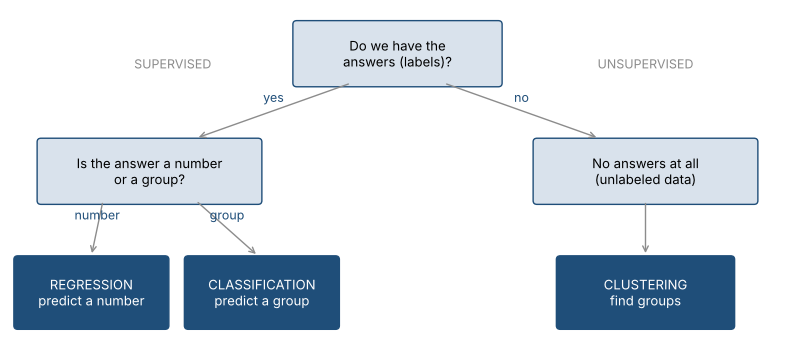

In [2]:
# Decorative diagram: just run it, no need to read the code line by line.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.4); ax.axis("off")
def box(x, y, w, h, text, dark=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=BLUE if dark else "#D9E2EC", ec=BLUE))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.5, color="white" if dark else "black")
def arrow(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=GRAY))
    if label: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, label, fontsize=9, color=BLUE, ha="center")
box(3.7, 3.4, 2.6, 0.8, "Do we have the\nanswers (labels)?")
box(0.4, 1.8, 2.8, 0.8, "Is the answer a number\nor a group?")
box(6.8, 1.8, 2.8, 0.8, "No answers at all\n(unlabeled data)")
arrow(4.4, 3.4, 2.4, 2.65, "yes"); arrow(5.6, 3.4, 7.6, 2.65, "no")
box(0.1, 0.1, 1.9, 0.9, "REGRESSION\npredict a number", dark=True)
box(2.3, 0.1, 1.9, 0.9, "CLASSIFICATION\npredict a group", dark=True)
box(7.1, 0.1, 2.2, 0.9, "CLUSTERING\nfind groups", dark=True)
arrow(1.2, 1.8, 1.05, 1.05, "number"); arrow(2.4, 1.8, 3.2, 1.05, "group"); arrow(8.2, 1.8, 8.2, 1.05)
ax.text(2.1, 3.6, "SUPERVISED", fontsize=9, color=GRAY, ha="center")
ax.text(8.2, 3.6, "UNSUPERVISED", fontsize=9, color=GRAY, ha="center")
plt.show()

**Cách đọc**

- **Con số:** ba loại ở hàng dưới cùng.
- **Bức tranh:** đây là một cái cây hỏi đáp hai tầng. Hai loại bên trái có **đáp án sẵn** nên gọi chung là **học có giám sát** (supervised): máy học giống học sinh có thầy chấm bài. Loại bên phải **không có đáp án** nên gọi là **học không giám sát** (unsupervised): máy phải tự khám phá.
- **Câu hỏi tiếp:** ba chặng sau lần lượt chạy thử từng loại bằng dữ liệu thật.

## Chặng 1: Hồi quy, đáp án là một con số

**Câu hỏi:** câu hỏi của chị Hạnh thuộc loại nào, và nó trông thế nào trong code?

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
diabetes = load_diabetes(as_frame=True, scaled=False).frame
reg = LinearRegression().fit(diabetes[["bmi"]], diabetes["target"])
print("Predicted score for BMI 30:", round(reg.predict(pd.DataFrame({"bmi": [30]}))[0]))

Predicted score for BMI 30: 189


**Giải thích từng dòng**

- `from ... import ... (hai dòng đầu)`: (đã học ở A1) lấy hàm mở dữ liệu và máy hồi quy tuyến tính.
- `diabetes = load_diabetes(as_frame=True, scaled=False).frame`: (đã học ở A2) nạp bảng bệnh nhân đái tháo đường, đặt tên `diabetes`.
- `reg = LinearRegression().fit(diabetes[["bmi"]], diabetes["target"])`: (đã học ở A1) học đoán điểm tiến triển từ BMI.
- `print("Predicted score for BMI 30:", round(reg.predict(pd.DataFrame({"bmi": [30]}))[0]))`: (đã học ở A1) đoán cho bệnh nhân BMI 30 rồi làm tròn. Cả chuỗi `predict(...)` rồi `[0]` rồi `round(...)` được gộp thành một biểu thức.

**Cách đọc**

- **Con số:** máy trả lời một con số khoảng 189.
- **Bức tranh:** đáp án có thể là bất kỳ số nào trên một thang liên tục (150, 189,3, 201...). Vì đáp án là **số**, ta chấm bằng *khoảng cách giữa đoán và thật* (sai lệch trung bình, như A1 đến A5). Loại bài toán này gọi là **hồi quy** (regression).
- **Dùng khi:** đoán giá nhà, doanh thu, nhiệt độ ngày mai, thời gian giao hàng, điểm tiến triển bệnh...

**Mang về chặng 1:** đáp án là một **con số** thì đó là hồi quy; chấm bằng sai lệch.

## Chặng 2: Phân loại, đáp án là một nhóm đã biết

**Câu hỏi:** bác sĩ Lan hỏi *lành hay ác*. Đáp án là hai nhóm, không phải một con số. Làm thế nào?

Dữ liệu là 569 khối u, mỗi khối u có 30 số đo từ ảnh tế bào. Mỗi khối u có nhãn **ác tính** (malignant) hoặc **lành tính** (benign) do bác sĩ xác nhận.

In [4]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer(as_frame=True)
print(dict(zip(cancer.target_names.tolist(), [int((cancer.target == 0).sum()), int((cancer.target == 1).sum())])))
print("Label 0 means:", cancer.target_names[0], "| label 1 means:", cancer.target_names[1])

{'malignant': 212, 'benign': 357}
Label 0 means: malignant | label 1 means: benign


**Giải thích từng dòng**

- `from sklearn.datasets import load_breast_cancer`: lấy hàm mở bộ dữ liệu 569 khối u kèm theo thư viện.
- `cancer = load_breast_cancer(as_frame=True)`: mở bộ dữ liệu dưới dạng bảng. Biến `cancer` là một **gói** nhiều thứ: `cancer.frame` là bảng, `cancer.target` là cột nhãn, `cancer.target_names` là tên các nhãn.
- `print(dict(zip(cancer.target_names, [...])))`: đếm số khối u mỗi nhóm. `zip` ghép tên nhóm với số đếm (đã học `zip` ở A3); `dict(...)` đổi các cặp thành từ điển; `.tolist()` và `int(...)` chỉ để in cho gọn. Phép đếm `(cancer.target == 0).sum()` cho biết có bao nhiêu nhãn bằng 0.
- `print("Label 0 means:", ...)`: nhãn là **số** (0 và 1), còn `target_names` cho biết số đó nghĩa là gì: 0 là ác tính, 1 là lành tính. Hãy nhớ điều này, vì dễ nhầm.

In [5]:
from sklearn.model_selection import train_test_split
features = ["mean radius", "mean concave points"]
X = cancer.frame[features]
y = cancer.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**Giải thích từng dòng**

- `from sklearn.model_selection import train_test_split`: (đã học ở A4) lấy hàm chia sổ.
- `features = ["mean radius", "mean concave points"]`: chọn hai cột số đo để dễ vẽ hình: bán kính trung bình của khối u, và mức độ lõm của viền (càng lõm càng đáng ngờ).
- `X = cancer.frame[features]`: bảng đề gồm hai cột đó.
- `y = cancer.target`: cột nhãn 0/1.
- `X_train, X_test, y_train, y_test = train_test_split(..., stratify=y)`: (đã học `train_test_split` ở A4). Tùy chọn **mới**: `stratify=y` bắt hai phần chia **giữ cùng tỉ lệ nhãn**. Ở đây khoảng 63% lành, 37% ác. Không `stratify` thì có thể tập thi tình cờ ít ca ác hơn hẳn, làm điểm méo.

In [6]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print("Accuracy on new cases:", round(clf.score(X_test, y_test), 3))

Accuracy on new cases: 0.86


**Giải thích từng dòng**

- `from sklearn.linear_model import LogisticRegression`: lấy máy **hồi quy logistic**. Tên gọi là "hồi quy" nhưng nó dùng để **phân loại**: nó tính **xác suất** thuộc mỗi nhóm rồi chọn nhóm có xác suất cao hơn.
- `clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)`: tạo máy và học. `clf` viết tắt của classifier (máy phân loại). `max_iter=1000` là **số vòng luyện tối đa** (máy học bằng cách lăn dần xuống đáy như chiếc bát ở A1; nếu hết vòng mà chưa xuống tới đáy thì sklearn cảnh báo). 1000 vòng là dư cho bài này.
- `round(clf.score(X_test, y_test), 3)`: `score` của máy phân loại là **độ chính xác** (accuracy): tỉ lệ ca đoán **đúng nhóm**. Khác với máy hồi quy (không có khái niệm "đúng tuyệt đối").

**Cách đọc**

- **Con số:** máy đoán đúng khoảng **86%** ca trong tập thi.
- **Bức tranh:** 86% nghe tốt, nhưng cần một mốc so sánh. Nếu máy luôn đoán *"lành"* cho mọi ca thì đúng khoảng 63% (vì 63% ca là lành). Mốc lười này sẽ được tính ngay bên dưới.
- **Điều khác với hồi quy:** đáp án là nhóm nên ta chấm bằng **đúng hay sai**, không phải khoảng cách.

In [7]:
from sklearn.dummy import DummyClassifier
lazy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Always guess the common group:", round(lazy.score(X_test, y_test), 3))

Always guess the common group: 0.632


**Giải thích từng dòng**

- `from sklearn.dummy import DummyClassifier`: bản **phân loại** của máy mốc (ở A5 ta dùng `DummyRegressor` cho hồi quy).
- `lazy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)`: máy luôn đoán **nhóm phổ biến nhất** trong tập học (`most_frequent`), bỏ qua đề bài.
- `print("Always guess the common group:", ...)`: độ chính xác của mốc lười.

**Cách đọc:** mốc lười đúng khoảng 63%, máy đúng khoảng 86%, tức máy hơn mốc đáng kể. Nhưng *độ chính xác* chưa nói hết câu chuyện, vì **hai kiểu sai có cái giá rất khác nhau**. Hãy đếm riêng từng kiểu sai:

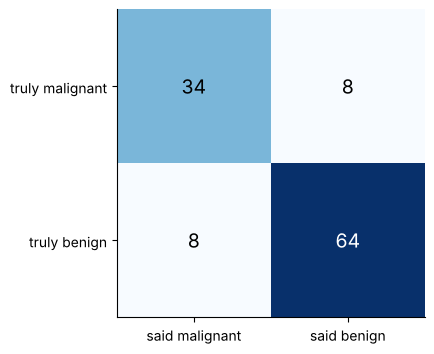

In [8]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, clf.predict(X_test))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["said malignant", "said benign"]); plt.yticks([0, 1], ["truly malignant", "truly benign"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > 40 else "black")
plt.show()

**Giải thích từng dòng**

- `from sklearn.metrics import confusion_matrix`: lấy hàm lập **ma trận nhầm lẫn**.
- `cm = confusion_matrix(y_test, clf.predict(X_test))`: bảng 2x2 đếm ca theo (nhóm thật, nhóm máy đoán). **Dòng** là nhóm thật, **cột** là nhóm máy đoán, theo đúng thứ tự nhãn 0 (ác) rồi 1 (lành).
- `plt.imshow(cm, cmap="Blues")`: (đã học `imshow` ở A2, `cmap` ở A3) tô đậm nhạt theo số ca.
- `plt.xticks([0, 1], [...]); plt.yticks([0, 1], [...])`: gắn tên cho hai cột và hai dòng để đọc cho đúng.
- `for i in range(2): for j in range(2): plt.text(...)`: (đã học ở A3) viết số ca lên từng ô, chữ trắng trên ô đậm.

**Cách đọc**

- **Con số:** ô trên trái 34 ca ác máy báo đúng là ác; ô dưới phải 64 ca lành báo đúng là lành; ô trên phải **8 ca ác bị máy báo nhầm là lành (bỏ sót)**; ô dưới trái 8 ca lành bị báo nhầm là ác (báo động giả).
- **Bức tranh:** hai ô sai có cùng số ca (8 và 8) nhưng **hậu quả khác nhau hoàn toàn**. Báo động giả: bệnh nhân lo lắng và làm thêm xét nghiệm, tốn kém nhưng an toàn. Bỏ sót: một khối u ác bị cho về nhà như không có gì, nguy hiểm đến tính mạng.
- **Hệ quả:** bác sĩ Lan sẽ chấp nhận *báo động giả nhiều hơn* để đổi lấy *bỏ sót ít hơn*. Điều chỉnh được không? Được, bằng cách thay đổi **ngưỡng quyết định**.

In [9]:
proba_benign = clf.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.3, 0.96, 0.05)
missed, alarms = [], []
for t in thresholds:
    called_benign = proba_benign > t
    missed.append(((y_test == 0) & called_benign).sum())
    alarms.append(((y_test == 1) & ~called_benign).sum())

**Giải thích từng dòng**

- `proba_benign = clf.predict_proba(X_test)[:, 1]`: `predict_proba` trả về **xác suất** thay vì nhóm: một bảng hai cột, cột 0 là xác suất ác, cột 1 là xác suất lành. `[:, 1]` lấy **cột số 1** (dấu hai chấm nghĩa là "mọi dòng"): xác suất lành của từng ca.
- `thresholds = np.arange(0.3, 0.96, 0.05)`: dãy ngưỡng từ 0,3 đến 0,95, mỗi bước 0,05. Máy chỉ gọi một ca là **lành** nếu xác suất lành **lớn hơn ngưỡng**. Ngưỡng mặc định của `predict` là 0,5.
- `missed, alarms = [], []`: hai danh sách trống: số ca ác bị **bỏ sót**, số ca lành bị **báo động giả**.
- `called_benign = proba_benign > t`: dãy Đúng/Sai: ca nào máy gọi là lành ở ngưỡng `t`.
- `missed.append(((y_test == 0) & called_benign).sum())`: `&` nghĩa là **và** (cả hai điều kiện cùng đúng) khi áp lên dãy Đúng/Sai. Đếm ca **thật sự ác** (`y_test == 0`) **và** bị gọi là lành: đó là ca bỏ sót.
- `alarms.append(((y_test == 1) & ~called_benign).sum())`: đếm ca **thật sự lành** và **không** bị gọi là lành (`~` là đảo): đó là báo động giả.

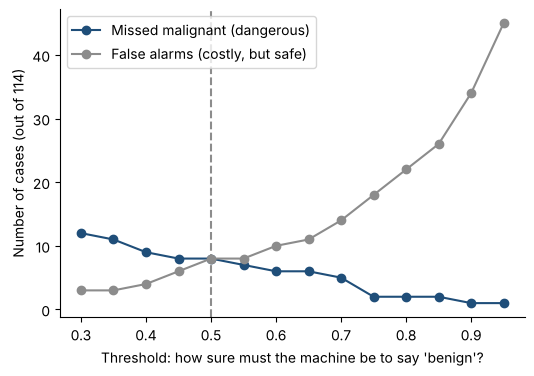

In [10]:
plt.plot(thresholds, missed, "o-", color=BLUE, label="Missed malignant (dangerous)")
plt.plot(thresholds, alarms, "o-", color=GRAY, label="False alarms (costly, but safe)")
plt.axvline(0.5, color=GRAY, linestyle="--")
plt.xlabel("Threshold: how sure must the machine be to say 'benign'?")
plt.ylabel("Number of cases (out of 114)")
plt.legend(); plt.show()

**Giải thích từng dòng**

- `plt.plot(thresholds, missed, "o-", color=BLUE, label="...")`: (đã học) đường số ca bỏ sót theo ngưỡng.
- `plt.plot(thresholds, alarms, "o-", color=GRAY, label="...")`: đường số báo động giả.
- `plt.axvline(0.5, color=GRAY, linestyle="--")`: vạch dọc nét đứt ở ngưỡng mặc định 0,5.
- `plt.xlabel(...); plt.ylabel(...); plt.legend(); plt.show()`: ghi tên trục, hiện chú giải và hình.

**Cách đọc**

- **Con số:** ở ngưỡng 0,5 có 8 ca bỏ sót và 8 báo động giả. Nâng ngưỡng lên 0,8 thì bỏ sót chỉ còn **2** nhưng báo động giả tăng lên **22**. Nâng lên 0,9 thì bỏ sót còn 1, báo động giả vọt lên 34.
- **Bức tranh:** hai đường đi ngược nhau như bập bênh: nâng ngưỡng giảm nguy hiểm nhưng tăng chi phí. *Không có ngưỡng nào làm cả hai bằng 0.* Chọn ngưỡng là một quyết định về **giá của từng kiểu sai**, không phải một quyết định kỹ thuật. Bác sĩ Lan có thể nói: "Chỉ cho về nhà khi máy chắc từ 80% trở lên là lành" và chấp nhận 22 ca phải xét lại.
- **Một điều thành thật:** đây chỉ là 114 ca trong tập thi, mỗi con số dao động theo cách chia (A4). Hình dáng bập bênh thì ổn định; con số cụ thể thì không.

Và nếu cho máy nhìn nhiều cột hơn thì sao?

In [11]:
all_X = cancer.frame.drop(columns="target")
a, b, c, d = train_test_split(all_X, y, test_size=0.2, random_state=42, stratify=y)
clf_all = LogisticRegression(max_iter=10000).fit(a, c)
print("Accuracy with all 30 columns:", round(clf_all.score(b, d), 3))

Accuracy with all 30 columns: 0.965


**Giải thích từng dòng**

- `all_X = cancer.frame.drop(columns="target")`: (đã học ở A2) bảng đề đủ 30 cột (bỏ cột nhãn).
- `a, b, c, d = train_test_split(..., stratify=y)`: chia theo cùng cách (cùng hạt giống, cùng `stratify`) nên tập thi là **đúng những ca ấy**, so sánh công bằng.
- `clf_all = LogisticRegression(max_iter=10000).fit(a, c)`: học trên 30 cột. `max_iter` tăng lên 10000 vì bài toán lớn hơn cần nhiều vòng luyện hơn.
- `print("Accuracy with all 30 columns:", round(clf_all.score(b, d), 3))`: độ chính xác trên tập thi.

**Cách đọc:** với 30 cột, độ chính xác lên khoảng **96%**, cao hơn hẳn 86% của hai cột. Quy luật quen thuộc từ A1: *thêm thông tin đúng chỗ thì máy đoán tốt hơn*.

**Mang về chặng 2:** đáp án là **một nhóm** thì đó là phân loại; chấm bằng độ chính xác, nhưng phải xem **từng kiểu sai** vì giá khác nhau. Ngưỡng quyết định là cái núm để đổi kiểu sai này lấy kiểu sai kia.

## Chặng 3: Phân cụm, không có đáp án, máy tự tìm nhóm

**Câu hỏi:** nếu nhóm nghiên cứu nhận một đợt mẫu **chưa có nhãn**, máy có thể làm gì?

Ta giả vờ giấu cột nhãn đi. Máy chỉ có hai số đo của mỗi khối u. Việc của nó là **chia các khối u thành hai nhóm sao cho trong mỗi nhóm các khối u giống nhau nhất**. Thuật toán dễ hiểu nhất tên là **K-means** (K là số nhóm cần tìm).

In [12]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X)
groups = km.labels_
print("Cases per cluster:", np.bincount(groups))

Cases per cluster: [427 142]


**Giải thích từng dòng**

- `from sklearn.cluster import KMeans`: lấy máy K-means từ module `cluster` (chuyên về phân cụm).
- `km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X)`: `n_clusters=2` là **số nhóm ta yêu cầu** (máy không tự biết nên có mấy nhóm). `n_init=10` nghĩa là thử **10 lần khởi đầu khác nhau** rồi giữ cách chia tốt nhất, để tránh một lần xui. `random_state=42` là hạt giống. `.fit(X)` chỉ nhận **đề bài**, không có `y`: đây là điểm khác biệt cốt lõi của học không giám sát.
- `groups = km.labels_`: `labels_` (có gạch dưới vì chỉ có sau `fit`) là **số hiệu cụm** (0 hoặc 1) mà máy gán cho từng khối u.
- `print("Cases per cluster:", np.bincount(groups))`: `np.bincount` đếm có bao nhiêu phần tử mang mỗi số hiệu. Số hiệu cụm chỉ là *tên* do máy đặt, không có nghĩa "0 là ác".

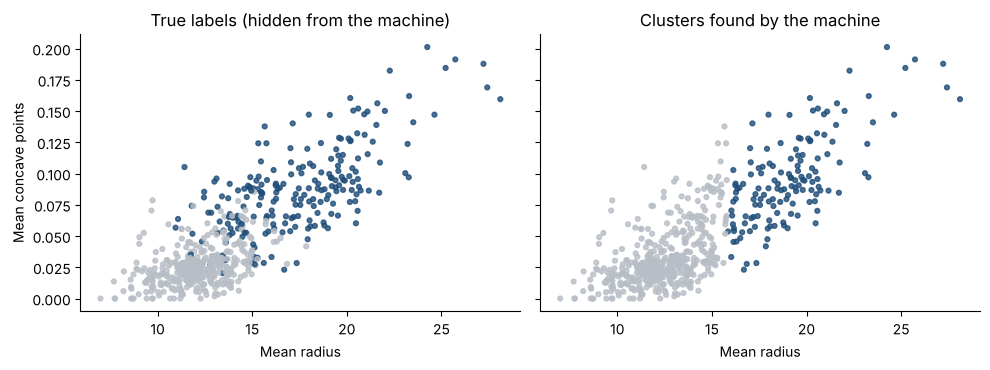

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=np.where(y == 0, BLUE, "#B8BEC6"), s=12, alpha=0.8)
axes[1].scatter(X.iloc[:, 0], X.iloc[:, 1], c=np.where(groups == 1, BLUE, "#B8BEC6"), s=12, alpha=0.8)
axes[0].set_title("True labels (hidden from the machine)"); axes[1].set_title("Clusters found by the machine")
for ax in axes: ax.set_xlabel("Mean radius")
axes[0].set_ylabel("Mean concave points")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)`: (đã học) hai ô cạnh nhau chung trục dọc.
- `axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=np.where(y == 0, BLUE, "#B8BEC6"), s=12, alpha=0.8)`: `X.iloc[:, 0]` là cách lấy **cột đầu tiên** theo vị trí (mọi dòng, cột số 0). `c=...` là **màu của từng chấm**. `np.where(y == 0, BLUE, xám)` là "nếu nhãn bằng 0 (ác) thì xanh đậm, ngược lại thì xám nhạt". `alpha=0.8` làm chấm hơi trong để thấy chỗ chồng nhau.
- `axes[1].scatter(X.iloc[:, 0], X.iloc[:, 1], c=np.where(groups == 1, BLUE, "#B8BEC6"), s=12, alpha=0.8)`: cùng các điểm đó, nhưng tô theo **cụm máy tìm ra** (cụm số 1 là cụm nhỏ, tô xanh đậm).
- `axes[0].set_title(...); axes[1].set_title(...)`: đặt tiêu đề cho hai ô.
- `for ax in axes: ax.set_xlabel(...)`: ghi tên trục ngang cho cả hai ô trong một dòng.

**Cách đọc**

- **Con số:** máy chia 569 khối u thành hai cụm, một cụm lớn khoảng 427 và một cụm nhỏ khoảng 142.
- **Bức tranh:** so hai ô: **không dùng nhãn nào mà máy vẫn chia ra một nhóm khá giống nhóm ác**. Điều này cho thấy trong dữ liệu có **cấu trúc thật** (khối u ác thường lớn và viền lõm hơn). Nhưng ranh giới không hoàn hảo: nhiều khối u ác nằm lẫn trong cụm lớn.
- **Đối chiếu với nhãn thật** (chỉ để kiểm tra, vì máy không được thấy nhãn):

In [14]:
pd.crosstab(y.map({0: "truly malignant", 1: "truly benign"}), groups, rownames=["truth"], colnames=["cluster"])

cluster,0,1
truth,,
truly benign,351,6
truly malignant,76,136


**Giải thích từng dòng**

- `y.map({0: "truly malignant", 1: "truly benign"})`: `.map({...})` **đổi từng giá trị** theo từ điển: số 0 thành chữ "truly malignant", số 1 thành chữ "truly benign", để bảng đọc cho dễ.
- `pd.crosstab(..., groups, rownames=[...], colnames=[...])`: `crosstab` đếm **chéo** hai thứ: mỗi dòng là nhóm thật, mỗi cột là cụm máy tìm. `rownames`, `colnames` đặt tên cho hai chiều.

**Cách đọc**

- **Con số:** cụm nhỏ gần như toàn ca ác (khoảng 136 trên 142), cụm lớn có 351 ca lành nhưng cũng lẫn 76 ca ác. Tính chung, cụm khớp với nhãn thật khoảng **86%**, gần ngang máy phân loại hai cột ở chặng 2.
- **Bức tranh:** máy không biết "ác" hay "lành" nghĩa là gì, nó chỉ thấy **hai đám mây** trong dữ liệu. Chính người nhìn kết quả mới đặt tên: "cụm nhỏ này có vẻ là ác". Phân cụm cho ta *gợi ý khám phá*, không phải *đáp án*.
- **Điều thành thật:** cụm lớn có 76 ca ác lẫn vào. Nếu dùng phân cụm để quyết định ai cần xét lại trước, ta vẫn bỏ sót rất nhiều. Khi đã có nhãn, phân loại (chặng 2) là công cụ đúng. Phân cụm đáng giá khi *chưa có nhãn*, hoặc để **khám phá nhóm chưa ai nghĩ tới**.
- **Một chi tiết kỹ thuật** (để dành cho B4): cột bán kính có số lớn (7 đến 28) còn cột độ lõm số nhỏ (0 đến 0,2), nên K-means gần như chỉ nhìn bán kính. Tip pro ở cuối bài cho thấy chuẩn hóa cải thiện kết quả ra sao.

**Mang về chặng 3:** không có đáp án thì dùng **phân cụm**. Máy chỉ nhận đề bài (không có `y`), tự chia nhóm theo độ giống nhau, và số hiệu cụm chỉ là tên. Người phải diễn giải ý nghĩa.

## Chặng 4: Cùng dữ liệu, đổi câu hỏi, đổi loại bài toán

**Câu hỏi:** loại bài toán là đặc tính của dữ liệu, hay của câu hỏi?

Hãy lấy lại bộ dữ liệu bệnh nhân ở chặng 1, nơi ta đã hỏi *"điểm tiến triển bao nhiêu?"* (hồi quy). Giờ đổi câu hỏi thành *"bệnh nhân này có nặng hay không?"* với quy ước **nặng nếu điểm trên 140** (xấp xỉ trung vị).

In [15]:
severe = (diabetes["target"] > 140).astype(int)
D_train, D_test, s_train, s_test = train_test_split(diabetes.drop(columns="target"), severe, test_size=0.2, random_state=42, stratify=severe)
clf_sev = LogisticRegression(max_iter=5000).fit(D_train, s_train)
print("Accuracy:", round(clf_sev.score(D_test, s_test), 3), "| always guess one group:", round(max(s_test.mean(), 1 - s_test.mean()), 3))

Accuracy: 0.742 | always guess one group: 0.506


**Giải thích từng dòng**

- `severe = (diabetes["target"] > 140).astype(int)`: (đã học `astype(int)` ở A2) biến điểm số thành **nhóm**: 1 nếu nặng (điểm trên 140), 0 nếu không. Cùng một cột, hai cách đặt câu hỏi.
- `D_train, D_test, s_train, s_test = train_test_split(..., stratify=severe)`: chia sổ, giữ tỉ lệ hai nhóm cân bằng.
- `clf_sev = LogisticRegression(max_iter=5000).fit(D_train, s_train)`: học phân loại "nặng hay không" từ 10 cột.
- `print("Accuracy:", ..., "| always guess one group:", round(max(s_test.mean(), 1 - s_test.mean()), 3))`: độ chính xác, kèm mốc lười: `s_test.mean()` là tỉ lệ nhóm nặng; `max(p, 1 - p)` là tỉ lệ của nhóm đông hơn, tức mốc đoán nhóm phổ biến nhất.

**Cách đọc**

- **Con số:** máy đoán đúng khoảng **74%** ca "nặng hay không", so với mốc lười khoảng 51%.
- **Bức tranh:** cùng một bộ bệnh nhân, ta đã chuyển từ **hồi quy** sang **phân loại** chỉ bằng cách đổi câu hỏi. Cái giá: ta *vứt thông tin*. Điểm 141 và điểm 300 đều thành "nặng", điểm 139 và điểm 30 đều thành "không nặng". Một người ở điểm 139 và một người ở 141 bị xếp hai nhóm khác hẳn dù gần như giống nhau.
- **Quy tắc chọn:** loại bài toán nên theo **quyết định cần ra**. Chị Hạnh cần *xếp hạng 20 người nặng nhất* nên hồi quy hợp hơn. Nếu quy định là *"nặng thì phải nhập viện"* (có/không) thì phân loại hợp hơn.

Tổng hợp thành một bảng để mang về:

| | **Hồi quy** | **Phân loại** | **Phân cụm** |
|---|---|---|---|
| **Có nhãn không?** | Có (là số) | Có (là nhóm) | Không |
| **Câu hỏi mẫu** | Bao nhiêu? | Thuộc nhóm nào? | Có những nhóm nào? |
| **Ví dụ trong bài** | Điểm tiến triển | Lành hay ác | Chia khối u thành cụm |
| **Máy đã gặp** | `LinearRegression` | `LogisticRegression` | `KMeans` |
| **Cách chấm** | Sai lệch trung bình | Độ chính xác và từng kiểu sai | Đối chiếu với kiến thức ngoài |
| **Mốc lười** | Đoán trung bình | Đoán nhóm phổ biến nhất | Không có mốc chuẩn |
| **Học ở phần** | B | C | F |

**Và học sâu, học tăng cường nằm ở đâu?** Chúng không phải loại bài toán thứ tư mà là **công cụ và cách học khác**. Học sâu (mạng nơ-ron) là một họ mô hình mạnh có thể giải cả hồi quy, phân loại và nhiều thứ khác. Học tăng cường là cách học khi máy hành động và nhận phần thưởng (chơi cờ, điều khiển robot) chứ không học từ bảng ví dụ có đáp án.

## Phán quyết và bài học nghề

**Phán quyết cho ba người ở đầu bài.**

- **Chị Hạnh** (đoán số, xếp hạng): hồi quy. Đã có từ A1 đến A5.
- **Bác sĩ Lan** (lành hay ác): phân loại. Máy 30 cột đúng khoảng 96%; chọn ngưỡng theo giá của từng kiểu sai, ví dụ chỉ cho về nhà khi máy chắc từ 80% trở lên là lành, đổi lại phải xét lại thêm khoảng 22 ca báo động giả. Máy chỉ *gợi ý*, bác sĩ quyết định.
- **Nhóm nghiên cứu** (mẫu chưa nhãn): phân cụm để khám phá. Kết quả là gợi ý để người diễn giải, không phải đáp án.

**Bài học nghề.**

1. **Hỏi hai câu để xếp loại:** có nhãn không, và nhãn là số hay nhóm.
2. **Loại bài toán là lựa chọn về câu hỏi.** Hãy theo quyết định cần ra, đừng theo thói quen.
3. **Độ chính xác chưa đủ.** Với phân loại, hãy đếm riêng từng kiểu sai và hỏi kiểu nào đắt hơn.
4. **Máy không biết ý nghĩa.** Phân cụm cho ra nhóm, con người mới đặt tên và quyết định.
5. **Khi nào không nên dùng máy học:** khi quy tắc đơn giản đủ tốt, khi dữ liệu quá ít, hoặc khi hậu quả sai quá nặng mà không có người kiểm lại.

**Một điều thành thật:** mọi bộ dữ liệu trong bài là dữ liệu mẫu đã làm sạch. Ngoài đời, nhãn "lành/ác" cũng có sai sót, và cái ta đo được thường không phải cái ta thật sự muốn đoán.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Hai câu hỏi để xếp loại: có nhãn không? nhãn là số hay nhóm? |
| 1 | Hồi quy: đáp án là số, chấm bằng sai lệch. |
| 2 | Phân loại: đáp án là nhóm; chấm bằng độ chính xác nhưng phải đếm từng kiểu sai. Ngưỡng quyết định đổi kiểu sai này lấy kiểu kia. |
| 3 | Phân cụm: không có đáp án, máy tự chia nhóm, người đặt tên. `fit` chỉ nhận `X`. |
| 4 | Cùng dữ liệu có thể đặt thành loại bài toán khác nhau. Chọn theo quyết định cần ra. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Học theo bài có đáp án sẵn | học có giám sát (supervised) | `fit(X, y)` |
| Tự khám phá không có đáp án | học không giám sát (unsupervised) | `fit(X)` |
| Đoán một con số | hồi quy (regression) | `LinearRegression` |
| Đoán một nhóm | phân loại (classification) | `LogisticRegression` |
| Tự chia nhóm | phân cụm (clustering) | `KMeans` |
| Tỉ lệ ca đoán đúng nhóm | độ chính xác (accuracy) | `clf.score(X, y)` |
| Bảng đếm đúng và sai theo từng kiểu | ma trận nhầm lẫn (confusion matrix) | `confusion_matrix` |
| Mức chắc chắn để gọi là lành | ngưỡng quyết định (threshold) | `predict_proba(...) > t` |
| Chia sổ giữ tỉ lệ nhóm | chia phân tầng (stratified split) | `stratify=y` |

**Thử thách tự làm**

1. Ở chặng 2, đổi hai cột `features` thành `["mean texture", "mean smoothness"]` rồi chạy lại. Độ chính xác thay đổi thế nào, và máy còn hơn mốc lười không? (Gợi ý: cột nào mô tả hình dạng rõ hơn thì thường cho điểm tốt hơn.)
2. Ở chặng 3, đổi `n_clusters=2` thành 3 rồi 4. Hình tô màu thay đổi ra sao? Có cách nào biết số cụm "đúng" không? (Gợi ý: khi không có nhãn, không có đáp án đúng tuyệt đối; phần F sẽ dạy các thước đo.)
3. Ở chặng 4, đổi ngưỡng "nặng" từ 140 thành 200. Độ chính xác của máy thay đổi thế nào, và mốc lười thì sao? (Gợi ý: lớp nặng giờ ít hơn nên mốc lười sẽ cao hơn. Nhớ sửa cả hai chỗ dùng số 140 nếu có.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Dùng hai câu hỏi để xếp một yêu cầu vào hồi quy, phân loại hay phân cụm.
- [ ] Phân biệt `fit(X, y)` và `fit(X)`.
- [ ] Đọc được ma trận nhầm lẫn và nói được kiểu sai nào đắt hơn trong tình huống cụ thể.
- [ ] Giải thích được ngưỡng quyết định và cái giá khi thay đổi nó.
- [ ] Biết phân cụm chỉ gợi ý nhóm, còn ý nghĩa là do con người diễn giải.
- [ ] Nêu được khi nào không nên dùng máy học.

## Phần thưởng (Tip pro): Chuẩn hóa giúp K-means ra sao


K-means đo "giống nhau" bằng **khoảng cách**. Nếu một cột có số lớn (bán kính 7 đến 28) và một cột có số nhỏ (độ lõm 0 đến 0,2), cột lớn lấn át. Cách chữa là **chuẩn hóa**: đưa mọi cột về cùng thang (trừ trung bình, chia độ lệch chuẩn). Buổi B4 sẽ dạy đầy đủ. Chạy ô dưới để thấy kết quả trước.

In [16]:
X_scaled = (X - X.mean()) / X.std()
km_scaled = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_scaled)
agree = max((km_scaled.labels_ == (y == 0)).mean(), (km_scaled.labels_ != (y == 0)).mean())
print(f"Clusters match the true labels in {agree:.0%} of cases (before scaling: 86%)")

Clusters match the true labels in 90% of cases (before scaling: 86%)


**Giải thích từng dòng**

- `X_scaled = (X - X.mean()) / X.std()`: **chuẩn hóa** bằng phép tính trực tiếp trên bảng: mỗi cột trừ trung bình của chính nó rồi chia độ lệch chuẩn (`std`). Sau đó mỗi cột có trung bình 0 và độ phân tán 1, nên không cột nào lấn át cột nào. Pandas tự áp phép tính cho từng cột.
- `km_scaled = KMeans(...).fit(X_scaled)`: chạy K-means trên bảng đã chuẩn hóa.
- `agree = max((km_scaled.labels_ == (y == 0)).mean(), (km_scaled.labels_ != (y == 0)).mean())`: đo mức khớp với nhãn thật. Số hiệu cụm là tên tùy ý (cụm 0 có thể là nhóm ác hoặc nhóm lành), nên ta tính cả hai cách ghép (`==` và `!=`) rồi lấy cách khớp nhiều hơn bằng `max`. `.mean()` của dãy Đúng/Sai chính là **tỉ lệ Đúng**.
- `print(f"... {agree:.0%} ...")`: `:.0%` định dạng một số thành phần trăm làm tròn đến đơn vị.